# STAT 207 Homework 3 [50 points]

## Data Frame Cleaning and Quantitative Variable Descriptive Analytics

Due: Friday, February 3 by noon (11:59 am) CST*

*No late submissions accepted
<hr>

## <u>Case Study</u>: Steam Game Play and Purchase Analysis
Steam is the world's most popular PC Gaming hub. With a massive collection that includes everything from AAA blockbusters to small indie titles, great discovery tools can be super valuable for Steam. What can we learn about Steam gaming behavior?

The dataset we will be analyzing is comprised of a random sample of 500 steam users and their game play and purchase behaviors. It has the following columns:
* user_id
* game_name,
* activity:
    - purchase: indicating that the user has *purchased* the corresponding game
    - play: indicating that the user has *played* the corresponding game (for at least some amount of time.) 
* hours_played_if_play:
    - if the row corresponds to a 'play' activity, this number represents the number of hours the user has played the game
    - if the row corresponds to a 'purchase' activity, this number is always a 1 (and means nothing... it's a placeholder).
    
This is the same data that you worked with in Lab 2.

<hr>

## Package Imports

We'll import four Python packages that we've used so far and will need for this assignment.  Those packages are pandas, numpy, matplotlib.pyplot, and seaborn.  

Run the cell provided below to access the functions in these packages.

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Tutorial

*Hint*: we can index the output of the shape attribute like a list.  See the Tutorial provided below for an example.

You may find this helpful as you work on this Homework assignment.

In [3]:
#Tutorial
import pandas as pd
demo_df=pd.DataFrame({'a': [1,2,3], 'b': [4,5,6]})
demo_df

,a,b
0,1,4
1,2,5
2,3,6


In [4]:
#Tutorial
print(demo_df.shape)
print(demo_df.shape[0])
print(demo_df.shape[1])

(3, 2)
3
2


*Note*: you may have already completed Steps 1 & 2 below in Lab 2.  Be sure to repeat this analysis here, showing the full process so that we can follow your logic and thought process.

## 1. Read in the Data [1 point]

Read in the steam_sample.csv data.

In [5]:
df = pd.read_csv("steam_sample.csv",na_values='unknown')
df

,user_id,game_name,activity,hours_played_if_play
0,308653033,Unturned,purchase,1.0
1,308653033,Unturned,play,0.6
2,308653033,theHunter,purchase,1.0
3,144004384,Dota 2,purchase,1.0
4,144004384,Dota 2,play,22.0
...,...,...,...,...
7801,99096740,SimCity 4 Deluxe,play,0.2
7802,99096740,BioShock Infinite Burial at Sea - Episode 2,purchase,1.0
7803,99096740,The Elder Scrolls V Skyrim - Dawnguard,purchase,1.0
7804,99096740,The Elder Scrolls V Skyrim - Dragonborn,purchase,1.0


## 2. Cleaning the Data [5 points]

We plan to analyze the "hours_played_if_play" variable from the steam data.

Before beginning our analysis, we need to prepare the data.  To do so, one step is to check for missing data.  While doing so, be sure to pay careful attention to our variable of interest.

Complete the following steps to clean the data:

1. Identify values (if any) that have been encoded in the csv to represent a **missing value**.
2. Read in the csv file so that the missing values are written as NaN in the data.
3. Confirm that the "hours_played_if_play" is recognized as numerical values (either float64 or int64 type).
4. Delete any rows from your data that have missing values.
5. Report the number of observations dropped from the data.

In [6]:
df.isna()

,user_id,game_name,activity,hours_played_if_play
0,False,False,False,False
1,False,False,False,False
2,False,False,False,False
3,False,False,False,False
4,False,False,False,False
...,...,...,...,...
7801,False,False,False,False
7802,False,False,False,False
7803,False,False,False,False
7804,False,False,False,False


In [7]:
df.isna().sum()

user_id                 0
game_name               0
activity                0
hours_played_if_play    6
dtype: int64

In [8]:
df.dropna()

,user_id,game_name,activity,hours_played_if_play
0,308653033,Unturned,purchase,1.0
1,308653033,Unturned,play,0.6
2,308653033,theHunter,purchase,1.0
3,144004384,Dota 2,purchase,1.0
4,144004384,Dota 2,play,22.0
...,...,...,...,...
7801,99096740,SimCity 4 Deluxe,play,0.2
7802,99096740,BioShock Infinite Burial at Sea - Episode 2,purchase,1.0
7803,99096740,The Elder Scrolls V Skyrim - Dawnguard,purchase,1.0
7804,99096740,The Elder Scrolls V Skyrim - Dragonborn,purchase,1.0


In [9]:
df.dtypes

user_id                   int64
game_name                object
activity                 object
hours_played_if_play    float64
dtype: object

In [10]:
# 6 observations were dropped

## 3. Purchases & Played Games [4 points]

**a)** Separate the Steam data into two different data frames:

- one for the user-game entries that have been played
- one for the user-game entries that represent purchases

In [11]:
played= df[df.activity == "play"]
played

,user_id,game_name,activity,hours_played_if_play
1,308653033,Unturned,play,0.6
4,144004384,Dota 2,play,22.0
6,54103616,Counter-Strike Global Offensive,play,1028.0
8,54103616,Counter-Strike,play,1008.0
10,54103616,Left 4 Dead,play,148.0
...,...,...,...,...
7793,99096740,Crysis,play,5.3
7795,99096740,Assassin's Creed II,play,2.7
7797,99096740,Hitman Blood Money,play,1.3
7799,99096740,The Binding of Isaac Rebirth,play,0.7


In [12]:
purchased = df[df.activity == "purchase"]
purchased

,user_id,game_name,activity,hours_played_if_play
0,308653033,Unturned,purchase,1.0
2,308653033,theHunter,purchase,1.0
3,144004384,Dota 2,purchase,1.0
5,54103616,Counter-Strike Global Offensive,purchase,1.0
7,54103616,Counter-Strike,purchase,1.0
...,...,...,...,...
7800,99096740,SimCity 4 Deluxe,purchase,1.0
7802,99096740,BioShock Infinite Burial at Sea - Episode 2,purchase,1.0
7803,99096740,The Elder Scrolls V Skyrim - Dawnguard,purchase,1.0
7804,99096740,The Elder Scrolls V Skyrim - Dragonborn,purchase,1.0


**b)** What proportion of games purchased have been played?

In [13]:
proppurchased= played.count()/purchased.count()
proppurchased

user_id                 0.583046
game_name               0.583046
activity                0.583046
hours_played_if_play    0.582792
dtype: float64

## 4. A High Game User [10 points]

**a)** Extract the row, which represents a user-game combination, that has the **sixth** highest amount of total hours played in the dataset.

**To get full credit, you should do this in one line of code.**

In [14]:
superusers = played.nlargest(6, "hours_played_if_play").min()
superusers

user_id                       32749624
game_name               Counter-Strike
activity                          play
hours_played_if_play            2258.0
dtype: object

**b)** Filter the data to contain only the transactions (purchases and games played) for this user.  Display this data frame.

In [15]:
superuser6 = df[df.user_id == 32749624]
superuser6

,user_id,game_name,activity,hours_played_if_play
530,32749624,Counter-Strike,purchase,1.0
531,32749624,Counter-Strike,play,4814.0
532,32749624,Counter-Strike Global Offensive,purchase,1.0
533,32749624,Counter-Strike Global Offensive,play,117.0
534,32749624,Garry's Mod,purchase,1.0
535,32749624,Garry's Mod,play,4.0
536,32749624,H1Z1,purchase,1.0
537,32749624,H1Z1,play,1.8
538,32749624,Dota 2,purchase,1.0
539,32749624,Dota 2,play,0.5


**c)** Calculate the percentage of purchased games that this user actually played.  

**To get full credit, you should do this in one line of code using the dataframe created in part 4b**.

In [16]:
user6percplayed= (superuser6[superuser6.activity == "play"].count())/(superuser6[superuser6.activity == "purchase"].count())*100
user6percplayed

user_id                 19.230769
game_name               19.230769
activity                19.230769
hours_played_if_play    19.230769
dtype: float64

## 5. Distribution of Hours Played [9 points]

We will now focus on the time spent playing games.  

Generate a **frequency** histogram for the time spent playing an individual game by an individual user.  Make sure to include clear axes labels and titles on your graph.  Then, describe the distribution.

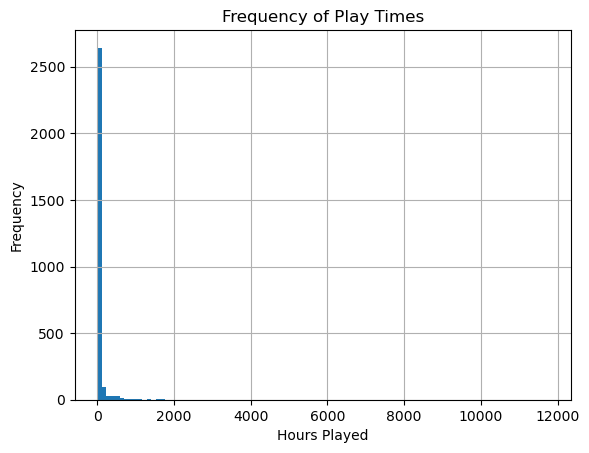

In [35]:
#Looking at only the higher number of hours makes the graph more readable. 
#played1 = played[played["hours_played_if_play"]>100]
#played1['hours_played_if_play'].hist(bins=200)
played['hours_played_if_play'].hist(bins=100)
plt.xlabel('Hours Played')
plt.ylabel('Frequency')
plt.title('Frequency of Play Times')
plt.show()

## 6. Low and High Game Users [5 points]

**a)** Calculate the minimum time spent playing a game in our data.  How many rows represent user-game combinations that were played for the minimum number of hours?

In [40]:
minplayed = played['hours_played_if_play'].min()
minplayed

0.1

0.1

**b)** Repeat the calculation from part a for the maximum time spent playing a game.

In [41]:
maxplayed = played['hours_played_if_play'].max()
maxplayed

11754.0

11754

## 7. Comparing Play Times of Two Games [16 points]

We want to compare the play times that users spent with two games of different genres:

- Counter-Strike is a first-person shooter game
- Sid Meier's Civilization V is a turn-based strategy game

**a)** First, filter the data to create two separate data frames that contain the play times for users of these two games.  How many users played each of these two games?  

*Note*: calculating the number of users with Python is sufficient; you do not need to report the number of users in a Markdown cell.

In [50]:
csgo = played[played.game_name == "Counter-Strike"]
csgo


,user_id,game_name,activity,hours_played_if_play
8,54103616,Counter-Strike,play,1008.0
142,95898619,Counter-Strike,play,2.4
226,87071236,Counter-Strike,play,31.0
313,76319436,Counter-Strike,play,3.7
531,32749624,Counter-Strike,play,4814.0
614,35729292,Counter-Strike,play,370.0
1428,54477968,Counter-Strike,play,15.2
1463,47164966,Counter-Strike,play,646.0
1535,14153959,Counter-Strike,play,2.0
1582,36611463,Counter-Strike,play,1.7


In [48]:
csgo.count()

user_id                 30
game_name               30
activity                30
hours_played_if_play    30
dtype: int64

In [52]:
civV = played[played.game_name == "Sid Meier's Civilization V"]
civV

,user_id,game_name,activity,hours_played_if_play
208,87071236,Sid Meier's Civilization V,play,197.0
799,99077905,Sid Meier's Civilization V,play,50.0
2479,80351692,Sid Meier's Civilization V,play,162.0
2548,88035166,Sid Meier's Civilization V,play,36.0
3091,134516625,Sid Meier's Civilization V,play,103.0
3534,220680498,Sid Meier's Civilization V,play,31.0
3679,117657402,Sid Meier's Civilization V,play,55.0
3808,80342096,Sid Meier's Civilization V,play,0.5
3924,118852041,Sid Meier's Civilization V,play,4.1
5028,113546110,Sid Meier's Civilization V,play,10.2


In [53]:
civV.count()

user_id                 20
game_name               20
activity                20
hours_played_if_play    20
dtype: int64

**b)** Stack the separate data frames from part **a** into one data frame.  Then, generate a side-by-side box plot of the play times for these two games.

In [54]:

fulldf = pd.concat([csgo, civV], ignore_index=True)
fulldf


,user_id,game_name,activity,hours_played_if_play
0,54103616,Counter-Strike,play,1008.0
1,95898619,Counter-Strike,play,2.4
2,87071236,Counter-Strike,play,31.0
3,76319436,Counter-Strike,play,3.7
4,32749624,Counter-Strike,play,4814.0
5,35729292,Counter-Strike,play,370.0
6,54477968,Counter-Strike,play,15.2
7,47164966,Counter-Strike,play,646.0
8,14153959,Counter-Strike,play,2.0
9,36611463,Counter-Strike,play,1.7


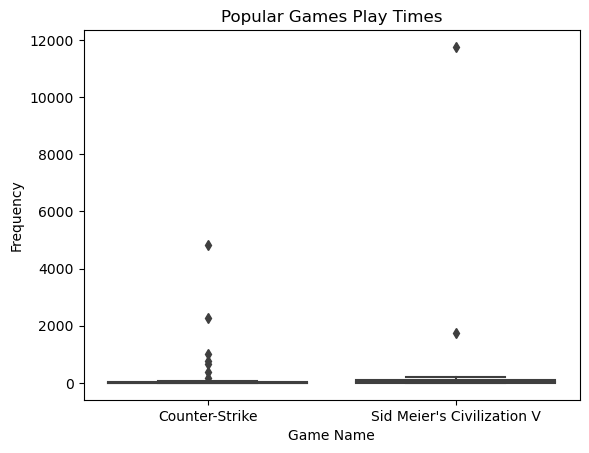

In [69]:
count = played.count()
sns.boxplot(x='game_name', y='hours_played_if_play', data=fulldf)
plt.xlabel('Game Name')
plt.ylabel('Frequency')
plt.title('Popular Games Play Times')
plt.show()

**c)** Calculate two sets of summary statistics, one for each game above.  Be sure to include the five number summary, mean, and standard deviation of the play times.

In [58]:
csgo.describe()

,user_id,hours_played_if_play
count,3.000000e+01,30.000000
mean,5.220795e+07,342.436667
std,4.010886e+07,964.242763
min,4.877411e+06,0.200000
25%,2.467427e+07,1.625000
50%,3.962333e+07,7.750000
75%,7.275932e+07,47.750000
max,1.590773e+08,4814.000000


In [59]:
civV.describe()

,user_id,hours_played_if_play
count,2.000000e+01,20.000000
mean,1.025223e+08,724.500000
std,4.992913e+07,2624.251107
min,9.245216e+06,0.500000
25%,7.554455e+07,10.875000
50%,8.755320e+07,43.000000
75%,1.207880e+08,109.750000
max,2.206805e+08,11754.000000


**d)** Finally, do the two distributions for the different games seem to be remarkably different?  Explain.

They do seem quite different. The counts are similar, but the mean and standard deviation for CivV is double that of csgo

Remember to keep all your cells and hit the save icon above periodically to checkpoint (save) your results on your local computer. Once you are satisified with your results restart the kernel and run all (Kernel -> Restart & Run All). **Make sure nothing has changed**. Checkpoint and exit (File -> Save and Checkpoint + File -> Close and Halt). Follow the instructions on the Homework 3 Canvas Assignment to submit your notebook to GitHub.